# Timestral - Zero-Shot Time-Series Forecasting on AMD

*with optional CPU-path.*

**Authors:** Shailen Sobhee  
**Knowledge level:** Beginner  
**Category:** Inference

> This tutorial does not assume prior time-series or forecasting background. Run the cells top to bottom. No model training and no per-dataset tuning are required.

## Introduction

**Model:** [Timestral](https://huggingface.co/collections/mistralai/timestral) by Mistral AI, a family of time-series foundation models for **zero-shot probabilistic forecasting**.

Give the model raw history (sales, power usage, sensor readings, demand, telemetry) and it predicts what comes next, with calibrated uncertainty, **without training a model per dataset**. At launch Timestral-209M ranked #1 among pretrained / zero-shot models on GIFT-Eval, TIME, and fev-bench.

This notebook is **GPU-first**: it loads `Timestral-209M` and forecasts on an **AMD Instinct MI300X** (ROCm), then shows the AMD Instinct story of forecasting an entire fleet of series on one GPU. Because Timestral is small, the **exact same notebook also runs on CPU**: flip one switch (next cell) to run `Timestral-5M` on an **AMD EPYC** CPU, no accelerator required. An optional section at the end covers the CPU thread and NUMA tuning that matters on a multi-socket AMD server.

This notebook:
1. Lets you pick GPU or CPU with one switch (auto-fallback to CPU if no GPU is visible).
2. Confirms the active device with a real capability check (a matmul on GPU, the math backend on CPU).
3. Loads Timestral (209M on GPU, 5M on CPU) once from the Hugging Face Hub.
4. Forecasts a held-out window with 21 probability quantiles and scores it.
5. Plots the forecast with uncertainty bands.
6. **GPU:** benchmarks fleet-scale batched throughput on one GPU.
7. **CPU (optional):** the thread sweet-spot sweep and the one-worker-per-NUMA-node pattern.

> New to AMD GPUs? See the repo README for how to get **free MI300X credits** on the AMD Developer Cloud.

## Preview: what the forecast looks like

Here is the zero-shot forecast you reproduce below: a held-out 2-day window predicted from 3 weeks of 15-minute history. The solid line is the median prediction; the shaded bands are the model's probability quantiles. **This is what you should see once the plotting cell runs.** Both images are embedded directly here so they are visible even before you execute anything.

**On AMD Instinct MI300X GPU (Timestral-209M):**

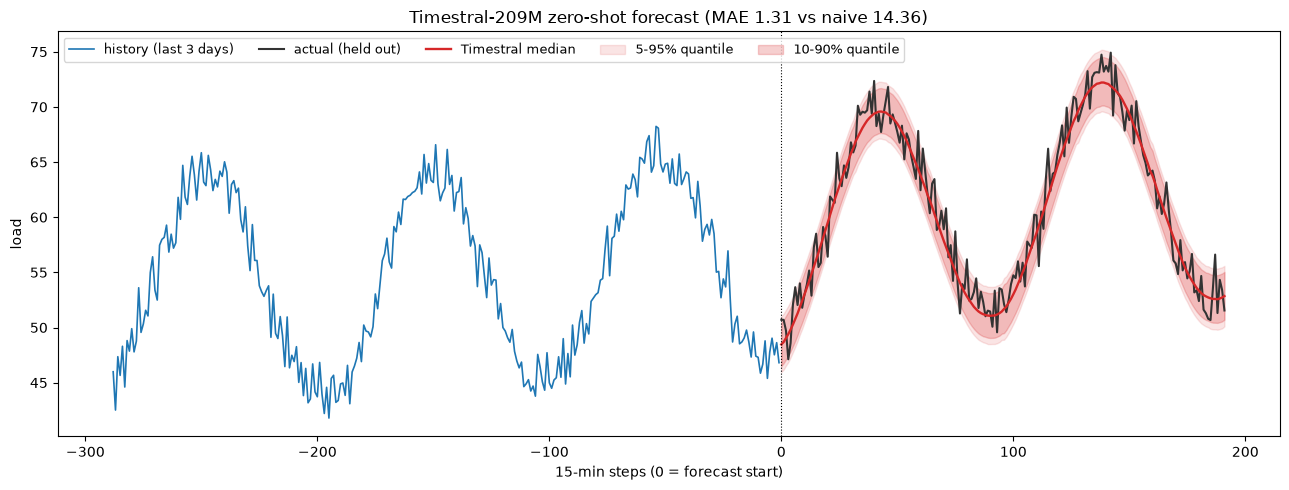

**On AMD EPYC CPU (Timestral-5M, the optional CPU path):**

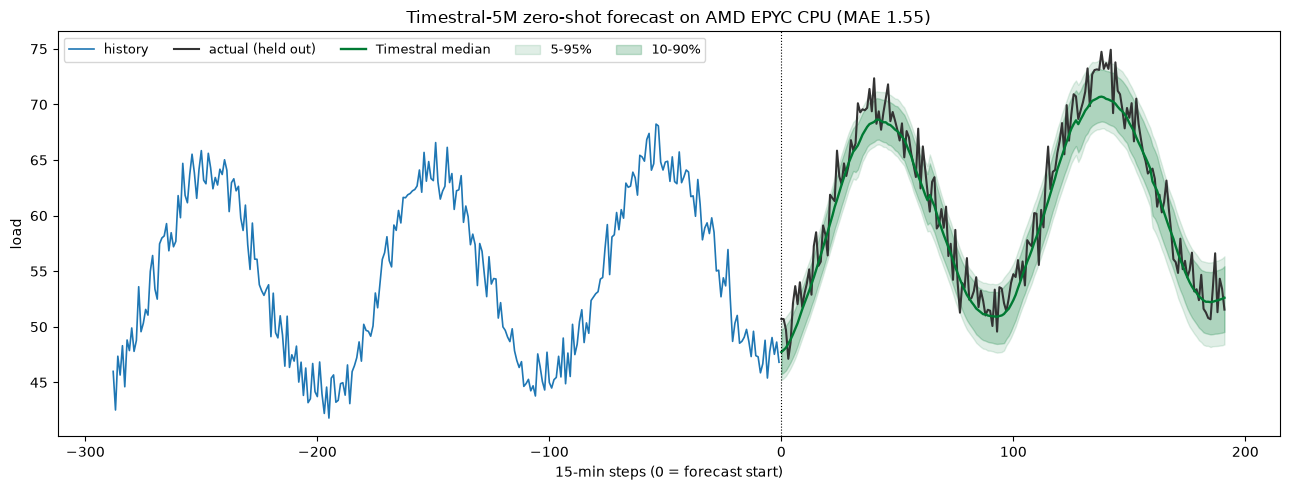

## 1. Choose your device: GPU (default) or CPU

This is the only cell you change to switch hardware.

- `RUN_ON = "gpu"` (default) runs `Timestral-209M` on an AMD Instinct GPU through ROCm. If no GPU is visible, it automatically falls back to CPU.
- `RUN_ON = "cpu"` runs `Timestral-5M` on the CPU (AMD EPYC), the lightweight edge-friendly path.

Everything after this cell reads `DEVICE` and `MODEL` and adapts, so the rest of the notebook is identical for both paths.

In [ ]:
RUN_ON = "gpu"   # "gpu" (default, Timestral-209M) or "cpu" (Timestral-5M)

import torch
_gpu = torch.cuda.is_available()
if RUN_ON == "gpu" and not _gpu:
    print("No GPU visible to PyTorch -> falling back to CPU.")
    RUN_ON = "cpu"

DEVICE = "cuda" if RUN_ON == "gpu" else "cpu"
MODEL  = "mistralai/Timestral-209M" if DEVICE == "cuda" else "mistralai/Timestral-5M"
print(f"RUN_ON={RUN_ON} | DEVICE={DEVICE} | MODEL={MODEL}")

## 2. Install

On the **GPU** path, PyTorch+ROCm is already installed in the AMD Developer Cloud ROCm image and the `rocm/pytorch` Docker image, so we only add Timestral and plotting libs.

On the **CPU** path, we install an AMD-accelerated stack for AMD EPYC: a CPU build of PyTorch plus [`zentorch`](https://pypi.org/project/zentorch/), AMD's ZenDNN plugin for PyTorch. `zentorch` is a `torch.compile` backend with EPYC-specific graph fusions and matmul kernels, and we enable it by default on CPU (Section 4). The cell below installs the right wheels for whichever device you selected.

For the best CPU throughput, also launch Jupyter with a faster OpenMP runtime and allocator preloaded (this must be set **before** the process starts, so it cannot be done from inside a cell):

```bash
pip install intel-openmp
LD_PRELOAD="$(python -c 'import glob,sys;print(glob.glob(sys.prefix+"/lib/libiomp5.so")[0])'):/usr/lib/x86_64-linux-gnu/libtcmalloc_minimal.so.4" \
  OMP_NUM_THREADS=$(nproc) jupyter lab
```

In [ ]:
import sys
if DEVICE == "cpu":
    # AMD EPYC CPU stack: CPU PyTorch + AMD ZenDNN plugin (zentorch).
    # zentorch pins a matching torch version, so install that torch, then zentorch.
    !{sys.executable} -m pip install -q torch==2.14.0 --index-url https://download.pytorch.org/whl/cpu
    !{sys.executable} -m pip install -q zentorch
# Timestral + plotting (both paths)
!{sys.executable} -m pip install -q "git+https://github.com/mistralai/timestral.git" numpy matplotlib pandas

## 3. Confirm the active AMD device

We verify the hardware the notebook will actually use. On the **GPU** path we run a real matmul so this is a true capability check, not just a version string (on ROCm, PyTorch exposes AMD GPUs through the same `torch.cuda` API). On the **CPU** path we report the oneDNN math backend, the thread count, and the CPU/NUMA topology.

In [ ]:
import torch, time, os, platform
print("torch", torch.__version__)
if DEVICE == "cuda":
    print("HIP", torch.version.hip, "| GPU count:", torch.cuda.device_count())
    print("device:", torch.cuda.get_device_name(0))
    a = torch.randn(4096, 4096, device="cuda"); b = torch.randn(4096, 4096, device="cuda")
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(20): c = a @ b
    torch.cuda.synchronize()
    dt = (time.time() - t0) / 20
    print(f"4096^3 matmul: {dt*1000:.2f} ms  (~{2*4096**3/dt/1e12:.1f} TFLOP/s, fp32)")
else:
    print("oneDNN (mkldnn) available:", torch.backends.mkldnn.is_available())
    print("default threads:", torch.get_num_threads())
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                print("CPU:", line.split(":", 1)[1].strip()); break
    except Exception:
        pass
    os.system("lscpu | grep -E 'Socket|NUMA node\\(s\\)|Core' || true")

### CPU only: set the thread sweet spot before loading

On CPU, a single Timestral forecast peaks at a modest thread count, and more threads past the sweet spot *regress* (measured in `CPU_BENCHMARKS.md`): about **8 threads for the 5M model**, ~16 for 209M. We cap the thread count here, before loading the model. This cell is a no-op on the GPU path. (NUMA pinning needs a separate process via `numactl`, shown in the optional CPU section at the end.)

In [ ]:
if DEVICE == "cpu":
    torch.set_num_threads(8)   # sweet spot for Timestral-5M on AMD EPYC; raise to 16 for 209M
    print("CPU threads set to", torch.get_num_threads())
else:
    print("GPU path: no thread capping needed.")

## 4. Load Timestral

`from_pretrained` downloads `config.json` + `model.safetensors` once to the Hugging Face cache. We load the model selected by your switch (`209M` on GPU, `5M` on CPU). You can swap in `Timestral-5M/28M/123M/209M` for smaller/faster or larger/stronger variants on either device.

On the **CPU** path we immediately compile the forecaster with AMD's ZenDNN backend (`torch.compile(backend="zentorch")`) so every forecast below runs through the EPYC-optimized kernels. The compile benefit grows with model size, and accuracy is unchanged.

In [ ]:
from timestral import TimestralForecaster
import time
t0 = time.time()
forecaster = TimestralForecaster.from_pretrained(MODEL, device=DEVICE)
print(f"Loaded {MODEL} onto {DEVICE} in {time.time()-t0:.1f}s")

# CPU path: accelerate with AMD ZenDNN (zentorch) by default.
if DEVICE == "cpu":
    import torch, zentorch  # noqa: F401
    mod = getattr(forecaster, "model", None) or getattr(forecaster, "module", None)
    if isinstance(mod, torch.nn.Module):
        compiled = torch.compile(mod, backend="zentorch")
        if hasattr(forecaster, "model"):
            forecaster.model = compiled
        else:
            forecaster.module = compiled
        print(f"Accelerated with AMD ZenDNN: zentorch {zentorch.__version__}, backend='zentorch'")
    else:
        print("Could not locate the inner nn.Module to compile; running eager zentorch.")

## 5. Build a realistic series and forecast it

We synthesize three weeks of 15-minute electricity-load-style data (daily + weekly seasonality + trend + noise), hold out the last two days as ground truth, and let Timestral forecast them zero-shot. The context shape is `(series, variates, time)`. This cell is identical on GPU and CPU.

In [ ]:
import numpy as np
rng = np.random.default_rng(7)
spd = 96                      # 15-min steps per day
H = 21 * spd                  # 3 weeks of history
horizon = 2 * spd             # forecast 2 days ahead
tt = np.arange(H + horizon)
base = (50
        + 10*np.sin(2*np.pi*tt/spd - 1.2)      # daily cycle
        + 4*np.sin(2*np.pi*tt/(7*spd))         # weekly cycle
        + 0.004*tt)                            # slow trend
full = base + rng.normal(0, 1.5, size=tt.shape)
context, truth = full[:H], full[H:H+horizon]

ctx = context.astype(np.float32)[None, None, :]      # (1, 1, T)
with torch.inference_mode():
    forecast = forecaster.forecast(ctx, prediction_length=horizon)
print("quantiles shape:", tuple(forecast.quantiles.shape),
      "= (series, variates, horizon, 21 quantile levels)")
print("quantile levels:", tuple(round(float(q), 2) for q in forecast.quantile_levels))

### Score the forecast

Mean Absolute Error of the median vs a naive "repeat the last value" baseline. Skill = how much error the model removes relative to that baseline.

In [ ]:
def to_np(x):
    return x.detach().float().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)

med   = to_np(forecast.median)[0, 0]
mae   = float(np.mean(np.abs(med - truth)))
naive = float(np.mean(np.abs(context[-1] - truth)))
print(f"median MAE     = {mae:.2f}")
print(f"naive-last MAE = {naive:.2f}")
print(f"skill vs naive = {1 - mae/naive:.1%}")

## 6. Plot the forecast with uncertainty bands

The green/red line is the median prediction; the shaded bands are the 5-95% and 10-90% quantile ranges Timestral produces. The plot colour follows the active device so you can tell the two runs apart.

In [ ]:
import matplotlib.pyplot as plt
q10, q90 = to_np(forecast.quantile(0.1))[0,0], to_np(forecast.quantile(0.9))[0,0]
q05, q95 = to_np(forecast.quantile(0.05))[0,0], to_np(forecast.quantile(0.95))[0,0]

colour = "#d62728" if DEVICE == "cuda" else "#007a33"
hw = "AMD Instinct MI300X GPU" if DEVICE == "cuda" else "AMD EPYC CPU"

plt.figure(figsize=(13, 5))
hx = np.arange(-3*spd, 0)
plt.plot(hx, context[hx], color="#1f77b4", lw=1.2, label="history (last 3 days)")
fx = np.arange(0, horizon)
plt.plot(fx, truth, color="#333", lw=1.5, label="actual (held out)")
plt.plot(fx, med, color=colour, lw=1.7, label="Timestral median")
plt.fill_between(fx, q05, q95, color=colour, alpha=0.12, label="5-95% quantile")
plt.fill_between(fx, q10, q90, color=colour, alpha=0.22, label="10-90% quantile")
plt.axvline(0, color="k", ls=":", lw=0.8)
plt.title(f"{MODEL.split('/')[-1]} zero-shot forecast on {hw} (MAE {mae:.2f} vs naive {naive:.2f})")
plt.xlabel("15-min steps (0 = forecast start)"); plt.ylabel("load")
plt.legend(ncol=5, fontsize=9, loc="upper left"); plt.tight_layout()
plt.show()

## 7. Fleet-scale throughput on one AMD GPU

The real AMD Instinct story: one GPU forecasts an **entire fleet** of series in a single batched pass. Below we forecast 1 -> 1024 independent series at once and measure series/second. The 192 GB of HBM on an MI300X lets you batch a large number of series without running out of memory.

This runs on either device, but it is the GPU's moment: on CPU you would instead scale out with one worker per NUMA node (see the optional section below).

In [ ]:
import time
dev_name = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "AMD EPYC CPU"
print(f"device: {dev_name}")
for B in [1, 64, 256, 1024]:
    batch = (base[None, None, :H] + rng.normal(0, 1.5, size=(B, 1, H))).astype(np.float32)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    with torch.inference_mode():
        _ = forecaster.forecast(batch, prediction_length=horizon)
    if DEVICE == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0
    print(f"{B:5d} series x {horizon} steps : {dt:6.2f} s = {B/dt:9.1f} series/s")

## 8. Optional: tuning the CPU path on AMD EPYC

> **This section is for the CPU path.** It is skipped automatically on GPU. Set `RUN_ON = "cpu"` at the top and re-run if you want to explore CPU scaling.

Two rules, both measured in `CPU_BENCHMARKS.md`:

1. **Keep each inference on one NUMA node.** Spreading one job across both sockets is *slower*, because the per-forecast working set is small and cross-socket memory traffic dominates.
2. **Cap threads at the sweet spot** (~8 for the 5M model, ~16 for 209M). More threads past that regress.

### 8a. Thread sweet-spot sweep (single kernel)

Within one process we can only change the thread count; NUMA pinning needs a fresh process via `numactl` (see 8b). This shows the diminishing returns directly.

In [ ]:
if DEVICE == "cpu":
    import time
    batch = (base[None, None, :H] + rng.normal(0, 1.5, size=(256, 1, H))).astype(np.float32)
    print(f"{MODEL.split('/')[-1]}, batch=256, throughput vs threads:")
    for thr in [4, 8, 16, 32]:
        torch.set_num_threads(thr)
        with torch.inference_mode():
            _ = forecaster.forecast(batch[:16], prediction_length=horizon)   # warm
            t0 = time.time(); _ = forecaster.forecast(batch, prediction_length=horizon); dt = time.time()-t0
        print(f"  {thr:3d} threads : {dt:6.3f} s = {256/dt:7.1f} series/s")
    torch.set_num_threads(8)   # restore the sweet spot
else:
    print("GPU path: skipping the CPU thread sweep. Set RUN_ON = \"cpu\" to run it.")

### 8b. Using the whole machine: one worker per NUMA node

Because a single forecast peaks at a modest thread count, the right way to use all cores on a 2-socket EPYC is to run **independent workers, each pinned to one NUMA node**, and split your series across them. From a shell:

```bash
# worker on socket 0, cores 0-15, memory on node 0
OMP_NUM_THREADS=16 numactl --cpunodebind=0 --membind=0 --physcpubind=0-15 python forecast_demo.py &

# worker on socket 1, cores 128-143, memory on node 1
OMP_NUM_THREADS=16 numactl --cpunodebind=1 --membind=1 --physcpubind=128-143 python forecast_demo.py &
wait
```

The repo's `bench/cpu_sweep.sh` automates the full sweep (latency vs threads, throughput vs threads, NUMA scaling, model-size sweep) and writes JSON results. See `CPU_BENCHMARKS.md` for the measured tables and the AMD EPYC vs AMD Instinct MI300X comparison.

## Next steps

- **Use your own data:** replace `context` with a real `(series, variates, time)` array. NaN marks missing values.
- **Covariates:** pass `past_covariates` / `known_covariates` (e.g. calendar, temperature) to `forecast(...)`. See the [Timestral README](https://github.com/mistralai/timestral).
- **Public benchmarks:** GIFT-Eval, TIME, fev-bench.
- **GPU vs CPU:** `Timestral-209M` on an AMD Instinct MI300X forecasts a whole fleet in one batched pass; `Timestral-5M` forecasts a single series in ~10 ms on an AMD EPYC CPU, great for edge deployment.

Built and verified on an **AMD Instinct MI300X** via the [AMD Developer Cloud](https://devcloud.amd.com/), with the CPU path verified on an **AMD EPYC** server.